<a href="https://colab.research.google.com/github/jppeirce/DSC210-Foundations-of-Data-Science/blob/main/Homework/HW07-supervised_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 7 SOLUTIONS: How Old Is This Abalone?

*Instructor version. Do not distribute.*

**DSC 210 Foundations of Data Science**

*Covers Module 11 (supervised learning: regression).*

```
ASK  ->  GET  ->  EXPLORE  ->  [ MODEL ]  ->  COMMUNICATE
```

References:
- Module 11 course notebook (linear regression, MAE / RMSE / $R^2$, residual plots, k-NN and tree regression, random forests, logistic regression, cross-validation)
- Abalone data: Nash, W. J., Sellers, T. L., Talbot, S. R., Cawthorn, A. J., and Ford, W. B. (1994). *The Population Biology of Abalone (Haliotis species) in Tasmania. I. Blacklip Abalone (H. rubra) from the North Coast and Islands of Bass Strait.* Sea Fisheries Division, Technical Report No. 48. Distributed through the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/1/abalone); this homework reads the copy at [github.com/jbrownlee/Datasets](https://github.com/jbrownlee/Datasets)

*Last major revision: 2026-11-08*

## Key Concepts

- Fit a line, and state its slope and intercept in the units of the problem
- Judge a regression with MAE, RMSE, $R^2$, a baseline, and a residual plot
- Compare a line with k-NN, a tree, and a random forest, and read feature importances
- Predict a probability with logistic regression, and find its decision boundary
- Compare models with cross-validation, and choose one honestly

## Instructions

**Total: 50 points.** Point values are listed with each problem.

- Cells marked `# RUN-TOGETHER` are complete; run them and read the output.
- Cells marked `# FILL-IN` contain blanks written as `____`.
- Cells marked `# ADAPT` are for you to write. Each one names a cell in the **Module 11 notebook**. Find that cell, copy it here, and change it to fit this problem (a different dataset, different columns, different names). Use the variable names the problem asks for, because later cells use them.
- Run the cells **in order**. Every figure must include a title and labeled axes.
- Most of the credit rides on your written answers. Quote specific numbers from your output.
- Submit the completed `.ipynb`, with all cells run and all figures visible, to Canvas.

---
## Part 0. Counting rings is slow (2 points)
---

Abalone are large sea snails, harvested for food and closely managed by fisheries agencies. To find an abalone's age, a biologist cuts through the shell, stains it, and counts the growth **rings** under a microscope; the age in years is about the number of rings plus 1.5. That is slow, careful work.

You work with the Tasmanian fisheries team that measured 4,177 abalone in the early 1990s. **Can quick measurements (size and weight) predict the ring count, so fewer shells need to be cut?**

| Column | Meaning |
| --- | --- |
| `sex` | `M` male, `F` female, `I` infant (too young to tell) |
| `length`, `diameter`, `height` | shell size (mm) |
| `whole` | weight of the whole abalone (g) |
| `shucked` | weight of the meat (g) |
| `viscera` | gut weight (g) |
| `shell` | weight of the dried shell (g) |
| `rings` | **the label:** number of growth rings |

In [1]:
# RUN-TOGETHER  (setup)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/abalone.csv'
columns = ['sex', 'length', 'diameter', 'height', 'whole', 'shucked', 'viscera', 'shell', 'rings']
abalone = pd.read_csv(url, header=None, names=columns)    # the file has no header row

measurements = ['length', 'diameter', 'height', 'whole', 'shucked', 'viscera', 'shell']
abalone[measurements] = abalone[measurements] * 200       # the file stores every measurement divided by 200

print('shape:', abalone.shape)
abalone.describe().round(1)

shape: (4177, 9)


,length,diameter,height,whole,shucked,viscera,shell,rings
count,4177.0,4177.0,4177.0,4177.0,4177.0,4177.0,4177.0,4177.0
mean,104.8,81.6,27.9,165.7,71.9,36.1,47.8,9.9
std,24.0,19.8,8.4,98.1,44.4,21.9,27.8,3.2
min,15.0,11.0,0.0,0.4,0.2,0.1,0.3,1.0
25%,90.0,70.0,23.0,88.3,37.2,18.7,26.0,8.0
50%,109.0,85.0,28.0,159.9,67.2,34.2,46.8,9.0
75%,123.0,96.0,33.0,230.6,100.4,50.6,65.8,11.0
max,163.0,130.0,226.0,565.1,297.6,152.0,201.0,29.0


**Problem 0.** (2 points)

(a) What does one row of `abalone` represent? What is the mean number of rings?

(b) Look at the `min` and `max` of `height`. Which values are physically impossible for a shell whose longest side is at most 163 mm? Run the next cell, which removes rows with a height of 0 or of 60 mm or more, and report how many abalone remain.

**Your answer:**

(a)

(b)

In [2]:
# RUN-TOGETHER  (Problem 0)
print('heights, smallest five:', abalone['height'].sort_values().head().round(1).tolist())
print('heights, largest five :', abalone['height'].sort_values().tail().round(1).tolist())

abalone = abalone[(abalone['height'] > 0) & (abalone['height'] < 60)].copy()
abalone['infant'] = (abalone['sex'] == 'I').astype(int)      # 1 for infants, 0 for adults
print('abalone kept:', len(abalone))

heights, smallest five: [0.0, 0.0, 2.0, 3.0, 3.0]
heights, largest five : [50.0, 50.0, 50.0, 103.0, 226.0]
abalone kept: 4173


> **SOLUTION**
>
> (a) One row is one abalone: its sex, seven size and weight measurements, and its ring count. The mean is about 9.9 rings (about 11.4 years).
>
> (b) Two abalone have a height of **0 mm**, which is impossible for a living shell, and one has a height of **226 mm**, taller than any shell is long (the longest is 163 mm). A second value, **103 mm**, is also far outside the rest (the next largest heights are 50 mm). These look like recording errors. After removing the four rows, **4,173** abalone remain.

---
## Part A. A line through the data (12 points)
---

### Problem A1. Fit the line (3 points)

**How many more rings does an abalone with a heavier shell tend to have?** Fit a line predicting `rings` from `shell`.

In [3]:
X = abalone[['shell']]
y = abalone['rings']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=210)

lin = LinearRegression().fit(X_train, y_train)
pred = lin.predict(X_test)

print('slope    :', round(lin.coef_[0], 4), 'rings per gram of shell')
print('intercept:', round(lin.intercept_, 2), 'rings')
print('observed shell weight range:', round(abalone['shell'].min(), 1), 'to', round(abalone['shell'].max(), 1), 'g')

slope    : 0.0725 rings per gram of shell
intercept: 6.49 rings
observed shell weight range: 0.3 to 201.0 g


(a) Finish the sentence: *"Each additional 10 grams of shell is associated with about ______ more rings."* (Multiply the slope by 10.)

(b) The intercept describes an abalone whose shell weighs 0 g. The lightest shells in the data weigh about 0.3 g, so this is barely outside the data. Is 6.5 rings a believable age for the tiniest abalone? (The table in A3 will help.)

(c) The line predicts about 28 rings for a 300 g shell. Name the problem with trusting that number.

**Your answer:**

(a)

(b)

(c)

> **SOLUTION**
>
> Slope 0.0725 rings per gram, intercept 6.49 rings, observed range 0.3 to 201.0 g.
>
> (a) Each additional 10 grams of shell is associated with about **0.7** more rings.
>
> (b) Not very. The line says a shell of almost nothing belongs to an abalone with about 6.5 rings (about 8 years), but the abalone with shells under 10 g average only 5.5 rings (A3 table), and many have far fewer. The intercept is barely an extrapolation; the trouble is that the line does not fit the small abalone well (A3 shows why).
>
> (c) 300 g is far above the heaviest shell in the data (201 g), so this is **extrapolation**: the line keeps climbing with no evidence that rings keep adding up at the same rate.

### Problem A2. How good is the line? (3 points)

In [4]:
print('MAE :', round(mean_absolute_error(y_test, pred), 2), 'rings')
print('RMSE:', round(mean_squared_error(y_test, pred) ** 0.5, 2), 'rings')
print('R2  :', round(r2_score(y_test, pred), 3))
print()
baseline = np.full_like(y_test, y_train.mean(), dtype=float)
print('baseline MAE (always predict the training mean):', round(mean_absolute_error(y_test, baseline), 2), 'rings')

MAE : 1.8 rings
RMSE: 2.48 rings
R2  : 0.404

baseline MAE (always predict the training mean): 2.33 rings


(a) Report MAE, RMSE, $R^2$, and the baseline MAE. By how many rings does the line improve on the baseline?

(b) The age is rings + 1.5 years. Translate the MAE into years. Would a fisheries manager be satisfied with that error for a single abalone? For the average of a whole catch?

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> (a) MAE about **1.80** rings, RMSE about **2.48** rings, $R^2$ = **0.404**; the baseline MAE is about **2.33** rings. The line improves the average miss by about half a ring.
>
> (b) Adding 1.5 to every ring count shifts predictions and actual values equally, so the error in years is the same: about **1.8 years** per abalone. That is large for one animal (an 8-year-old could be called 6 or 10), but the misses go in both directions, so the average over many abalone can be much closer. (Accept any reasoned judgment.)

### Problem A3. Read the residuals (3 points)

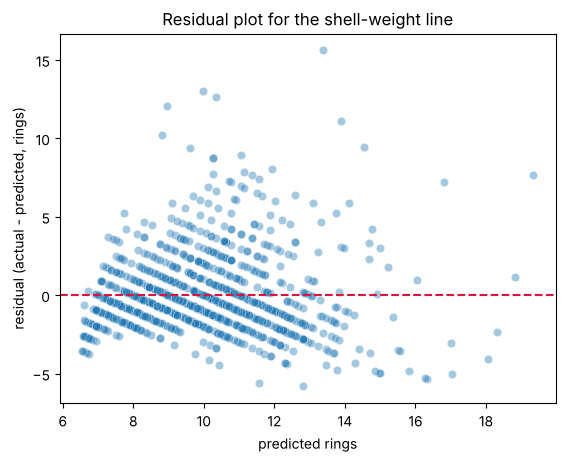

In [5]:
resid = y_test - pred

sns.scatterplot(x=pred, y=resid, alpha=0.4)
plt.axhline(0, color='crimson', linestyle='--')
plt.xlabel('predicted rings'); plt.ylabel('residual (actual - predicted, rings)')
plt.title('Residual plot for the shell-weight line')
plt.show()

In [6]:
# RUN-TOGETHER  (Problem A3): rings in shell-weight bands, all abalone
bands = pd.cut(abalone['shell'], [0, 10, 20, 40, 60, 80, 100, 210])
abalone.groupby(bands, observed=True)['rings'].agg(['mean', 'std', 'count']).round(2)

,mean,std,count
shell,,,
"(0, 10]",5.50,1.50,307
"(10, 20]",7.41,1.60,465
"(20, 40]",9.04,2.20,1019
"(40, 60]",10.56,2.67,1078
"(60, 80]",11.44,2.74,798
"(80, 100]",12.48,3.08,348
"(100, 210]",14.27,3.93,158


(a) Module 11, Section 3 shows three residual patterns: no pattern, a curve, and a fan. Which one is clearest in your plot, and what in the plot shows it? (The parallel diagonal stripes appear because ring counts are whole numbers; you can ignore them.)

(b) Use the `mean` column of the table to describe how rings grow with shell weight. Which second residual pattern does this suggest, and where does a straight line go wrong?

(c) Use the `std` column to explain the second pattern in biological terms: why might old abalone be harder to age from their weight?

**Your answer:**

(a)

(b)

(c)

> **SOLUTION**
>
> (a) A **fan**: the residuals spread out as the prediction grows; near a prediction of 7 rings they stay within a few rings of zero, while beyond 10 rings they range from about -5 to +15. (Instructor check, not printed in the notebook: the standard deviation of the residuals rises from about 1.6 rings in the lowest quarter of predictions to about 3.1 in the highest.)
>
> (b) Rings rise quickly at first (about 5.5 rings below 10 g, 7.4 at 10 to 20 g, 9.0 at 20 to 40 g) and then more slowly (10.6, 11.4, 12.5, 14.3 in the heavier bands). The gains per gram shrink, so the relationship bends: a **curve**. A straight line over-predicts the smallest abalone and does not follow the leveling off. (Instructor check: the average residual is about -0.6, +0.3, +0.4, and -0.5 across the four quarters of predictions, the arch of a curve.)
>
> (c) The spread of rings grows with shell weight (standard deviation about 1.5 rings below 10 g, about 3.9 above 100 g). A plausible reading is that growth slows as abalone age, so two abalone with the same heavy shell can differ by many years, while young abalone are still growing fast and their size tracks their age closely. (The data show the widening spread; the growth explanation is an interpretation.)

### Problem A4. Errors by hand (3 points)

Use the rounded line $\hat{y} = 6.5 + 0.07x$ for these four abalone, where $x$ is the shell weight in grams.

| abalone | shell $x$ (g) | actual rings | predicted | residual |
| --- | --- | --- | --- | --- |
| an infant | 5.0 | 4 |  |  |
| a female | 44.0 | 10 |  |  |
| a female | 91.0 | 12 |  |  |
| the oldest abalone in the data | 95.0 | 29 |  |  |

(a) Complete the table. Then compute the MAE and the RMSE of these four residuals. (Use Python as a calculator if you like.)

(b) What share of the **sum of absolute residuals** comes from the oldest abalone? What share of the **sum of squared residuals**? Which measure, MAE or RMSE, does one huge miss influence more, and why?

**Your answer:**

(a)

(b)

In [7]:
resid4 = np.array([4 - (6.5 + 0.07 * 5.0), 10 - (6.5 + 0.07 * 44.0),
                   12 - (6.5 + 0.07 * 91.0), 29 - (6.5 + 0.07 * 95.0)])
print('residuals:', resid4.round(2))
print('MAE :', round(np.abs(resid4).mean(), 2), '  RMSE:', round(np.sqrt((resid4 ** 2).mean()), 2))
print('oldest share of |residuals|:', round(abs(resid4[3]) / np.abs(resid4).sum(), 3),
      '  of squared residuals:', round(resid4[3] ** 2 / (resid4 ** 2).sum(), 3))

residuals: [-2.85  0.42 -0.87 15.85]
MAE : 5.0   RMSE: 8.07
oldest share of |residuals|: 0.793   of squared residuals: 0.965


> **SOLUTION**
>
> (a)
>
> | abalone | predicted | residual |
> | --- | --- | --- |
> | infant, 5.0 g | 6.85 | -2.85 |
> | female, 44.0 g | 9.58 | +0.42 |
> | female, 91.0 g | 12.87 | -0.87 |
> | oldest, 95.0 g | 13.15 | +15.85 |
>
> MAE $= (2.85 + 0.42 + 0.87 + 15.85)/4 \approx$ **5.00** rings. RMSE $= \sqrt{(2.85^2 + 0.42^2 + 0.87^2 + 15.85^2)/4} \approx \sqrt{65.07} \approx$ **8.07** rings.
>
> (b) The oldest abalone contributes 15.85 of 19.99, about **79%** of the absolute residuals, but 251.2 of 260.3, about **97%** of the squared residuals. RMSE squares each miss before averaging, so one huge miss dominates it; that is why RMSE is well above MAE here.

---
## Part B. Beyond a straight line (12 points)
---

### Problem B1. Let the model bend (4 points)

A3 showed the relationship bends. Models that do not assume a line might do better.

In [8]:
scaler = StandardScaler().fit(X_train)
Xtr_s, Xte_s = scaler.transform(X_train), scaler.transform(X_test)

print(f"{'k':>4}  {'MAE (rings)':>11}  {'R2':>7}")
for k in (1, 5, 25, 75):
    knn = KNeighborsRegressor(n_neighbors=k).fit(Xtr_s, y_train)
    q = knn.predict(Xte_s)
    print(f'{k:>4}  {mean_absolute_error(y_test, q):>11.2f}  {r2_score(y_test, q):>7.3f}')
print(f"{'line':>4}  {mean_absolute_error(y_test, pred):>11.2f}  {r2_score(y_test, pred):>7.3f}")
print()

for d in (1, 3, None):
    t = DecisionTreeRegressor(max_depth=d, random_state=0).fit(X_train, y_train)
    print(f'max_depth={str(d):9}  train R2={r2_score(y_train, t.predict(X_train)):.3f}   '
          f'test R2={r2_score(y_test, t.predict(X_test)):.3f}')

   k  MAE (rings)       R2
   1         2.39   -0.175


   5         1.91    0.304
  25         1.78    0.423
  75         1.76    0.419
line         1.80    0.404

max_depth=1          train R2=0.279   test R2=0.285
max_depth=3          train R2=0.421   test R2=0.402
max_depth=None       train R2=0.587   test R2=0.344


(a) Which k-NN models beat the line on test $R^2$, and by how much? Given how curved the A3 table looked, is the gain large or small? Use the fan in A3 to suggest why no model can get much better using shell weight alone.

(b) What happens at `k = 1`, and what does a negative $R^2$ mean? What happens to the unlimited tree?

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> (a) k = 25 ($R^2$ 0.423, MAE 1.78) and k = 75 ($R^2$ 0.419, MAE 1.76) beat the line ($R^2$ 0.404, MAE 1.80), but only by about 0.02 in $R^2$. The depth-3 tree (0.402) ties the line. Bending captures the curve, but the bigger problem is the fan: abalone with the same shell weight differ by many rings, and no function of shell weight alone can tell them apart.
>
> (b) k = 1 scores $R^2$ = **-0.175**, worse than always guessing the mean: each prediction copies one other abalone's ring count, noise and all. The unlimited tree fits its training abalone better (train $R^2$ 0.587) but does worse on the test set (0.344): it **overfits**.

### Problem B2. More measurements (4 points)

This is Activity 11.2 with the abalone data.

In [9]:
FEATURES = ['length', 'diameter', 'height', 'whole', 'shucked', 'viscera', 'shell', 'infant']

for label, cols in [('one feature (shell weight)', ['shell']),
                    ('all eight features', FEATURES)]:
    Xa, Xb, ya, yb = train_test_split(abalone[cols], abalone['rings'], test_size=0.25, random_state=210)
    print(f'--- {label} ---')
    for name, model in [('linear', LinearRegression()),
                        ('tree, depth 3', DecisionTreeRegressor(max_depth=3, random_state=0)),
                        ('tree, unlimited', DecisionTreeRegressor(random_state=0)),
                        ('random forest', RandomForestRegressor(n_estimators=200, random_state=0))]:
        model.fit(Xa, ya)
        print(f'  {name:17} train R2={r2_score(ya, model.predict(Xa)):.3f}   '
              f'test R2={r2_score(yb, model.predict(Xb)):.3f}')
    print()

--- one feature (shell weight) ---
  linear            train R2=0.391   test R2=0.404
  tree, depth 3     train R2=0.421   test R2=0.402


  tree, unlimited   train R2=0.587   test R2=0.344


  random forest     train R2=0.577   test R2=0.383

--- all eight features ---
  linear            train R2=0.544   test R2=0.540
  tree, depth 3     train R2=0.439   test R2=0.390
  tree, unlimited   train R2=1.000   test R2=0.153


  random forest     train R2=0.937   test R2=0.542



Use a forest of 200 trees.

(a) With all eight features, rank the four models by test $R^2$. How much did the linear model gain over its one-feature version?

(b) In Module 11 (cars) the forest clearly beat the line once more features were added. Does it here? Use the training scores to describe what the forest is doing that the line is not, and whether it pays off.

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> Blanks: `FEATURES`, `200`, `predict`.
>
> (a) Eight features: random forest **0.542**, linear **0.540**, depth-3 tree 0.390, unlimited tree 0.153. The linear model rose from 0.404 to 0.540.
>
> (b) No: the forest and the line are essentially tied on the test set (0.542 vs 0.540). The forest fits its training abalone far more closely (train $R^2$ 0.937 vs the line's 0.544), so it is capturing a great deal of detail, but almost none of that detail carries over to new abalone. More flexibility only pays off when there is real structure for it to find; here the remaining variation looks mostly like abalone-to-abalone differences the measurements cannot see.

### Problem B3. Which measurements matter? (4 points)

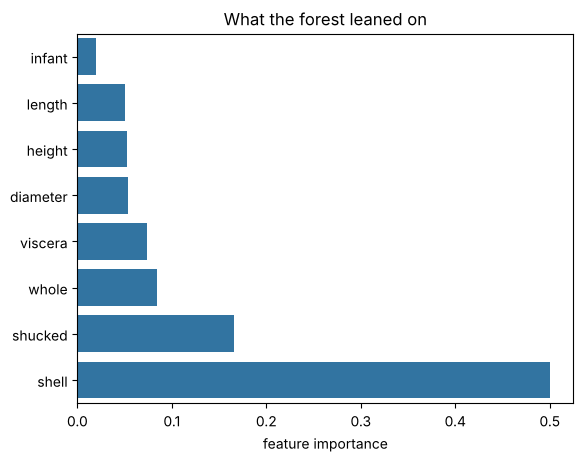

shell       0.500
shucked     0.166
whole       0.084
viscera     0.074
diameter    0.054
height      0.052
length      0.050
infant      0.020
dtype: float64


In [10]:
rf = RandomForestRegressor(n_estimators=200, random_state=0).fit(abalone[FEATURES], abalone['rings'])

importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
sns.barplot(x=importance.values, y=importance.index, orient='h')
plt.xlabel('feature importance'); plt.ylabel('')
plt.title('What the forest leaned on')
plt.show()
print(importance.round(3).sort_values(ascending=False))

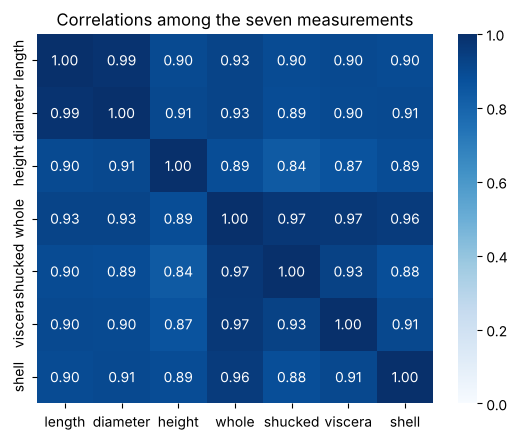

linear model coefficients (rings per unit):
length     -0.006
diameter    0.046
height      0.117
whole       0.044
shucked    -0.097
viscera    -0.056
shell       0.039
infant     -0.823
dtype: float64


In [11]:
# RUN-TOGETHER  (Problem B3)
sns.heatmap(abalone[measurements].corr(), annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title('Correlations among the seven measurements')
plt.show()

lin_all = LinearRegression().fit(abalone[FEATURES], abalone['rings'])
print('linear model coefficients (rings per unit):')
print(pd.Series(lin_all.coef_, index=FEATURES).round(3))

(a) Which feature does the forest lean on most, and by how much over the next one? Use the correlation heatmap to explain why the other five size and weight measurements get small importances even though each one, alone, is strongly related to rings.

(b) The linear model's coefficient on `shucked` (meat weight) is **negative**. Does that mean that more meat makes an abalone younger? Explain using the heatmap.

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> (a) `shell` (about 0.50), far ahead of `shucked` (about 0.17); the rest are below 0.09. The seven measurements are highly correlated with one another (0.84 to 0.99 in the heatmap), so they carry nearly the same information. Once the trees have split on shell weight, the others add little, and they share the leftover credit. A small importance does not mean a measurement is unrelated to age; it means a near-copy already did the work.
>
> (b) No. Each coefficient describes the change in predicted rings when that one feature changes **and all the others stay fixed**, and with features this correlated that situation hardly ever happens in real abalone. Holding whole weight and shell weight fixed, more meat means less of something else, and the line splits the shared information among the correlated columns in ways that can flip signs. On its own, heavier meat goes with *more* rings, as every weight does. Individual coefficients of strongly correlated features should not be read one at a time. (The precise reason for the negative sign is an interpretation; accept any answer that identifies correlated features as the cause.)

---
## Part C. Infant or adult? (8 points)
---

Infant abalone cannot yet be sexed, and fisheries rules generally aim to leave young animals in the water to grow. Can shell weight alone tell infants from adults? Here `infant` (1 or 0) is the label.

### Problem C1. Fit a logistic regression (4 points)

In [12]:
Xc, yc = abalone[['shell']], abalone['infant']
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.25, random_state=210, stratify=yc)
log = LogisticRegression(max_iter=2000).fit(Xc_tr, yc_tr)

print('share of infants:', round(yc.mean(), 3))
print('test accuracy :', round(log.score(Xc_te, yc_te), 3))
print('baseline      :', round(1 - yc.mean(), 3), '(always predict adult)')
print('intercept     :', round(log.intercept_[0], 2))
print('coefficient   :', round(log.coef_[0][0], 3), 'per gram of shell')

share of infants: 0.321
test accuracy : 0.789
baseline      : 0.679 (always predict adult)
intercept     : 2.13
coefficient   : -0.072 per gram of shell


(a) Report the test accuracy and the baseline. How much does the model add?

(b) The coefficient is negative. Say in words what that means for the chance that an abalone is an infant.

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> (a) 32.1% of the abalone are infants, so the baseline "always adult" scores about **0.679**. The model scores **0.789**, about 11 percentage points better.
>
> (b) Heavier shells make "infant" less likely: each extra gram of shell lowers $z$ by about 0.072, and so lowers the probability of being an infant. (Coefficients are on the $z$ scale, not probabilities; C2 turns them into probabilities.)

### Problem C2. Probabilities and the boundary, by hand (4 points)

Round the model to $z = 2.1 - 0.07\,x$, where $x$ is the shell weight in grams, and $p = \dfrac{1}{1 + e^{-z}}$ is the probability of being an infant. *(You will need $e^{-1.4} \approx 0.247$ and $e^{1.4} \approx 4.055$.)*

| shell $x$ (g) | $z$ | $p$ (infant) | predicted at 0.5 |
| --- | --- | --- | --- |
| 10 |  |  |  |
| 50 |  |  |  |

(a) Complete the table.

(b) Find the **decision boundary**: the shell weight where $p = 0.5$. Compare your two probabilities in the table, which sit the same distance from the boundary. What symmetry do you see?

(c) The fisheries team will use the model to decide which abalone to put back. Throwing back an adult loses one animal from the catch; keeping an infant harms the future population. Which mistake would they rather avoid, and should they move the threshold above or below 0.5 to do that?

**Your answer:**

(a)

(b)

(c)

> **SOLUTION**
>
> (a)
> - 10 g: $z = 2.1 - 0.7 = 1.4$; $p = 1/(1 + e^{-1.4}) \approx 1/1.247 \approx 0.80$; predicted **infant**.
> - 50 g: $z = 2.1 - 3.5 = -1.4$; $p = 1/(1 + e^{1.4}) \approx 1/5.055 \approx 0.20$; predicted **adult**.
>
> (b) $2.1 - 0.07x = 0$ gives $x = 30$ g. (With the unrounded coefficients it is about 29.5 g.) 10 g and 50 g are each 20 g from the boundary, and their probabilities add to 1 (0.80 and 0.20): the logistic curve is symmetric about the boundary, as in Activity 11.3 B.
>
> (c) Keeping an infant is the costlier mistake for the population, so they want to catch as many infants as possible (raise recall for "infant"). They should **lower** the threshold below 0.5, so that an abalone is put back even when the model is less sure it is an infant. The price is that more adults are thrown back too (lower precision).

---
## Part D. How much should we trust these scores? (10 points)
---

### Problem D1. Shuffle or not? (5 points)

In [13]:
for f, (train_idx, test_idx) in enumerate(KFold(5).split(X)):
    fold = abalone.iloc[test_idx]
    print(f'fold {f}: mean rings {fold["rings"].mean():.2f}   share of infants {fold["infant"].mean():.2f}')

scores = cross_val_score(LinearRegression(), X, y, cv=5, scoring='r2')
print()
print('unshuffled 5-fold R2:', np.round(scores, 3), ' mean:', round(scores.mean(), 3))

kf = KFold(5, shuffle=True, random_state=210)
shuffled = cross_val_score(LinearRegression(), X, y, cv=kf, scoring='r2')
print('shuffled 5-fold R2  :', np.round(shuffled, 3), ' mean:', round(shuffled.mean(), 3),
      ' spread:', round(shuffled.max() - shuffled.min(), 3))

fold 0: mean rings 11.41   share of infants 0.23
fold 1: mean rings 8.59   share of infants 0.43
fold 2: mean rings 10.49   share of infants 0.27
fold 3: mean rings 9.68   share of infants 0.31
fold 4: mean rings 9.51   share of infants 0.36

unshuffled 5-fold R2: [ 0.191 -0.056  0.383  0.41   0.293]  mean: 0.244
shuffled 5-fold R2  : [0.393 0.415 0.378 0.373 0.408]  mean: 0.393  spread: 0.042


(a) Without shuffling, which fold scores worst? Compare its mean rings and its share of infants with the other folds. What does that suggest about how the rows of the file are arranged?

(b) Report the shuffled scores, their mean, and their spread. How do they compare with the unshuffled ones?

(c) The documentation does not say how the rows were ordered. Suggest one plausible reason a file of field measurements might come grouped this way, and say why you cannot be sure.

**Your answer:**

(a)

(b)

(c)

> **SOLUTION**
>
> (a) Fold 1 scores worst ($R^2$ about **-0.06**; the unshuffled scores are about 0.19, -0.06, 0.38, 0.41, 0.29, mean 0.24). Fold 1 has the youngest abalone (mean 8.6 rings vs 9.5 to 11.4 in the others) and the most infants (43% vs 23% to 36%). The rows are not in random order: groups of similar abalone sit together in the file, so an unshuffled fold can be unlike the data the model trained on.
>
> (b) Shuffled: about 0.393, 0.415, 0.378, 0.373, 0.408; mean about **0.393**, spread about 0.04. Shuffling raises the mean and makes the five scores far more consistent, close to the single-split $R^2$ of 0.404.
>
> (c) Possible reasons: the abalone may have been entered in the order they were collected, by site or by trip, and different sites or seasons can have abalone of different ages. We cannot be sure because the data contain no site or date column and the documentation does not say. (Any plausible, hedged reason earns credit.)

### Problem D2. Choose a model honestly (5 points)

Module 11, Section 7.2 compares models with cross-validation. Here, keep a **test set** aside, run the cross-validation on the **training** abalone only, choose one model, and only then score it once on the test set.

In [14]:
X8_train, X8_test, y8_train, y8_test = train_test_split(abalone[FEATURES], abalone['rings'],
                                                        test_size=0.25, random_state=210)
kf = KFold(5, shuffle=True, random_state=210)

for name, model in [('linear regression', LinearRegression()),
                    ('tree, depth 3', DecisionTreeRegressor(max_depth=3, random_state=0)),
                    ('random forest', RandomForestRegressor(n_estimators=200, random_state=0))]:
    s = cross_val_score(model, X8_train, y8_train, cv=kf, scoring='r2')
    print(f'{name:>18}:  mean R2 = {s.mean():.3f}   folds {np.round(s, 3)}')

final = LinearRegression().fit(X8_train, y8_train)
final_pred = final.predict(X8_test)
print()
print('chosen model on the test abalone:  R2 =', round(r2_score(y8_test, final_pred), 3),
      '  MAE =', round(mean_absolute_error(y8_test, final_pred), 2), 'rings')

 linear regression:  mean R2 = 0.539   folds [0.536 0.546 0.522 0.559 0.531]
     tree, depth 3:  mean R2 = 0.406   folds [0.421 0.413 0.349 0.433 0.412]


     random forest:  mean R2 = 0.542   folds [0.543 0.562 0.465 0.574 0.568]

chosen model on the test abalone:  R2 = 0.54   MAE = 1.54 rings


(a) Report the mean cross-validated $R^2$ of each model. Is the difference between the top two larger than the spread of their fold scores?

(b) Which model would you choose, and why? Give at least two reasons, one of them **not** about $R^2$.

(c) Report your chosen model's test $R^2$ and MAE. Why is this one test number more trustworthy than trying all three on the test set and keeping the best?

**Your answer:**

(a)

(b)

(c)

> **SOLUTION**
>
> (a) Random forest about **0.542** (folds 0.465 to 0.574), linear regression about **0.539** (folds 0.522 to 0.559), depth-3 tree about 0.406. The forest and the line differ by about 0.003, far smaller than either one's fold spread (about 0.11 and 0.04): the difference is noise.
>
> (b) Sample: **linear regression**. Its accuracy is the same as the forest's within noise; its fold scores are steadier (spread 0.04 vs 0.11); it is fast; and it gives a formula the fisheries team can read, rather than 200 trees. (A student who chooses the forest and argues from its slightly higher mean can earn credit if they acknowledge the tie.)
>
> (c) Linear regression on the test abalone: $R^2$ about **0.540**, MAE about **1.54** rings. The test abalone played no part in the choice, so the number estimates performance on new abalone. Trying all three on the test set and keeping the best would let the test set influence the choice and make the reported number optimistic (Module 10, Section 2).

---
## Part E. Review and report (6 points)
---

### Problem E1. Code review: four quiet bugs (4 points)

A teammate wrote the cell below. **Every line runs.** For each numbered line, say what is wrong and how the output could give it away, then write a corrected version.

In [15]:
# RUN-TOGETHER  (a teammate's code: it runs, but every line has a problem)

# 1. R2 of the shell-weight line
print('1. R2:', round(r2_score(pred, y_test), 3))

# 2. RMSE of the shell-weight line
print('2. RMSE:', round(mean_squared_error(y_test, pred), 2), 'rings')

# 3. How many more rings per gram of shell?
lin_3 = LinearRegression().fit(X_train / 200, y_train)
print('3. rings per gram:', round(lin_3.coef_[0], 2))

# 4. How well will the chosen model do on new abalone?
print('4. R2 on new abalone:', round(r2_score(y8_train, final.predict(X8_train)), 3))

1. R2: -0.506
2. RMSE: 6.15 rings
3. rings per gram: 14.51
4. R2 on new abalone: 0.544


**Your answer:**

| Line | What is wrong | How the output gives it away |
| --- | --- | --- |
| 1 |  |  |
| 2 |  |  |
| 3 |  |  |
| 4 |  |  |

In [16]:
print('1.', round(r2_score(y_test, pred), 3))
print('2.', round(mean_squared_error(y_test, pred) ** 0.5, 2), 'rings')
print('3.', round(LinearRegression().fit(X_train, y_train).coef_[0], 4))     # use the weights in grams
print('4.', round(r2_score(y8_test, final.predict(X8_test)), 3))

1. 0.404
2. 2.48 rings
3. 0.0725
4. 0.54


> **SOLUTION**
>
> | Line | What is wrong | How the output gives it away |
> | --- | --- | --- |
> | 1 | The arguments are reversed: `r2_score` expects the actual values first, and $R^2$ compares against the mean of the first argument. | It prints a negative number, not the 0.404 from A2. |
> | 2 | That is the MSE, not the RMSE: the square root is missing. | 6.15 "rings" is far above the MAE of 1.80; MSE is in rings squared. |
> | 3 | It divides the weights by 200, undoing the setup step, so the units are not grams and the slope is 200 times too large. | 14.5 rings per gram is absurd: a 10 g shell would add 145 rings. |
> | 4 | It scores the model on its **training** abalone, not on new ones. | It reports about 0.54; here the training and test scores happen to be close for a linear model, so the output alone barely gives it away, which is exactly why the habit matters. |
>
> (For line 1 the printed value is about -0.51; for line 4 the printed value is about 0.544 against the test 0.540. Instructor check.)

### Problem E2. Report to the fisheries team (2 points)

In 3 to 4 sentences for biologists who have never fit a model: which model would you use to estimate ring counts from quick measurements, how far off should they expect it to be for a single abalone (in rings, then in years), and one honest caution, including whether they can stop cutting shells altogether.

**Your answer:**

> **SOLUTION**
>
> Sample answer. Use the linear model on all eight quick measurements: in cross-validation it was as accurate as a random forest of 200 trees, and it is a simple formula. On abalone it had not seen, it was off by about 1.5 rings (about 1.5 years) on a typical abalone, compared with about 2.3 rings for guessing the average. Its errors grow for older abalone (A3), so it is least reliable for exactly the large, old animals a fishery cares about. It cannot replace ring counts for individual animals, but it could reduce how many shells need to be cut, for example by aging a sample of each catch by hand and using the model for the rest.